# Wildfire Smoke Detection — Local Analysis Notebook

**Clean working copy (Windows / Python 3.12).** The original notebook is unchanged. This version focuses on loading existing checkpoints, verifying datasets, evaluating models, and inspecting errors. **It does not retrain models or overwrite existing datasets.**

Run cells from the top. Training code and original dataset-building code remain in the original notebook as a historical record.

## 1. Setup and local paths

In [4]:
from pathlib import Path
import re
from collections import Counter
import yaml
from ultralytics import YOLO

# The notebook is expected to be opened from the project root in VS Code.
PROJECT_DIR = Path.cwd().resolve()
DATASETS_DIR = PROJECT_DIR / "datasets"
MODELS_DIR = PROJECT_DIR / "models"
EXPERIMENTS_DIR = PROJECT_DIR / "experiments"
EVALUATION_DIR = PROJECT_DIR / "evaluations"
NEGATIVE_IMAGES_DIR = PROJECT_DIR / "negative_images"
NEGATIVE_LABELS_DIR = PROJECT_DIR / "negative_labels"

# Experiment 2 contains the existing 191-image validation split.
# Its training set also contains 180 negatives; do not treat it as the original baseline training set.
dataset_dir = DATASETS_DIR / "experiment_2"
validation_images_dir = dataset_dir / "images" / "val"
validation_labels_dir = dataset_dir / "labels" / "val"

for name, path in {"Project": PROJECT_DIR, "Dataset": dataset_dir,
                   "Validation images": validation_images_dir,
                   "Validation labels": validation_labels_dir}.items():
    print(f"{name}: {path} | exists={path.exists()}")

assert validation_images_dir.is_dir() and validation_labels_dir.is_dir(), "Validation folders not found."
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

Project: D:\Projects\Wildfire_Smoke_Project | exists=True
Dataset: D:\Projects\Wildfire_Smoke_Project\datasets\experiment_2 | exists=True
Validation images: D:\Projects\Wildfire_Smoke_Project\datasets\experiment_2\images\val | exists=True
Validation labels: D:\Projects\Wildfire_Smoke_Project\datasets\experiment_2\labels\val | exists=True


## 2. Validate dataset configuration (without changing the original YAML)

In [5]:
# Ultralytics needs an absolute dataset path on this Windows machine.
# Write a LOCAL evaluation-only YAML into evaluations/; leave original data.yaml untouched.
source_yaml = dataset_dir / "data.yaml"
assert source_yaml.exists(), f"Missing dataset config: {source_yaml}"
config = yaml.safe_load(source_yaml.read_text(encoding="utf-8"))
config["path"] = str(dataset_dir)
config["train"] = "images/train"
config["val"] = "images/val"
config["nc"] = 1
config["names"] = {0: "smoke"}
LOCAL_DATA_YAML = EVALUATION_DIR / "local_validation_data.yaml"
LOCAL_DATA_YAML.write_text(yaml.safe_dump(config, sort_keys=False), encoding="utf-8")
print(LOCAL_DATA_YAML.read_text(encoding="utf-8"))
print("Validation images:", len(list(validation_images_dir.glob("*.jpg"))))

path: D:\Projects\Wildfire_Smoke_Project\datasets\experiment_2
train: images/train
val: images/val
nc: 1
names:
  0: smoke

Validation images: 191


## 3. Load existing trained checkpoints — no retraining

In [6]:
# Existing models; baseline may be stored under models/ or smoke_training/baseline/weights/.
checkpoint_candidates = {
    "Baseline": [MODELS_DIR / "baseline_best.pt", PROJECT_DIR / "smoke_training" / "baseline" / "weights" / "best.pt"],
    "Experiment 1 — YOLO11n, 960": [EXPERIMENTS_DIR / "experiment_1_resolution960" / "weights" / "best.pt"],
    "Experiment 2 — negatives": [EXPERIMENTS_DIR / "experiment_2_negative_images" / "weights" / "best.pt"],
    "Experiment 3 — YOLO11s": [EXPERIMENTS_DIR / "experiment_3_yolo11s" / "weights" / "best.pt"],
}
models = {}
for name, candidates in checkpoint_candidates.items():
    found = next((p for p in candidates if p.is_file()), None)
    if found:
        models[name] = YOLO(str(found))
        print(f"Loaded {name}: {found.relative_to(PROJECT_DIR)}")
    else:
        print(f"Missing {name}: {[str(p) for p in candidates]}")

# Preserve familiar variable names used in earlier analyses.
baseline_model = models.get("Baseline")
experiment1_best = models.get("Experiment 1 — YOLO11n, 960")
experiment2_best = models.get("Experiment 2 — negatives")
experiment3_best = models.get("Experiment 3 — YOLO11s")

Loaded Baseline: models\baseline_best.pt
Loaded Experiment 1 — YOLO11n, 960: experiments\experiment_1_resolution960\weights\best.pt
Loaded Experiment 2 — negatives: experiments\experiment_2_negative_images\weights\best.pt
Loaded Experiment 3 — YOLO11s: experiments\experiment_3_yolo11s\weights\best.pt


## 4. Compare model validation metrics

Run when you want fresh results. Validation can take several minutes on a GTX 1660 SUPER. The 960-pixel models may require more GPU memory; use `device="cpu"` if you encounter a CUDA out-of-memory error. These metrics use the same **smoke-positive** validation split. A separate negative-only evaluation is still needed to measure false alarms.

In [10]:
from ultralytics import YOLO
from pathlib import Path
import pandas as pd
import re

# ============================================================
# LOAD SAVED MODEL CHECKPOINTS
# ============================================================

model_paths = {
    "Baseline": PROJECT_DIR / "models" / "baseline_best.pt",

    "Experiment 1 — YOLO11n, 960":
        EXPERIMENTS_DIR / "experiment_1_resolution960" / "weights" / "best.pt",

    "Experiment 2 — negatives":
        EXPERIMENTS_DIR / "experiment_2_negative_images" / "weights" / "best.pt",

    "Experiment 3 — YOLO11s":
        EXPERIMENTS_DIR / "experiment_3_yolo11s" / "weights" / "best.pt",

    "Experiment 4 — expanded negatives":
        EXPERIMENTS_DIR / "experiment_4_expanded_negatives_batch4_retry-5" / "weights" / "best.pt",
}

# Use each experiment's original inference resolution
model_sizes = {
    "Baseline": 640,
    "Experiment 1 — YOLO11n, 960": 960,
    "Experiment 2 — negatives": 640,
    "Experiment 3 — YOLO11s": 960,
    "Experiment 4 — expanded negatives": 960,
}

# ============================================================
# EVALUATE CHECKPOINTS
# ============================================================

metric_rows = []

for name, checkpoint in model_paths.items():

    # Verify the checkpoint exists before loading
    if not checkpoint.exists():
        print(f"Skipping {name}: checkpoint not found at {checkpoint}")
        continue

    print(f"\nEvaluating {name}...")

    # Load the saved weights from disk
    model = YOLO(str(checkpoint))

    # Evaluate against the original validation dataset
    metrics = model.val(
        data=str(LOCAL_DATA_YAML),
        split="val",
        imgsz=model_sizes[name],
        batch=1,
        device=0,
        plots=True,
        project=str(EVALUATION_DIR),
        name="local_" + re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_"),
        exist_ok=True,
    )

    # Extract precision, recall, and mAP
    p = metrics.box.mp
    r = metrics.box.mr

    metric_rows.append({
        "model": name,
        "precision": p,
        "recall": r,
        "f1_from_mean_p_r": 2 * p * r / (p + r) if p + r else 0,
        "mAP50": metrics.box.map50,
        "mAP50_95": metrics.box.map,
    })

# ============================================================
# DISPLAY RESULTS
# ============================================================

display(pd.DataFrame(metric_rows).round(4))


Evaluating Baseline...
Ultralytics 8.4.215  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1627.8±527.6 MB/s, size: 497.2 KB)
val: Scanning D:\Projects\Wildfire_Smoke_Project\datasets\experiment_2\labels\val.cache... 191 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 191/191  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 191/191 5.5it/s 34.8s<0.1s
                   all        191        191       0.62      0.341      0.369      0.164
Speed: 1.4ms preprocess, 19.8ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to D:\Projects\Wildfire_Smoke_Project\evaluations\local_baseline

Evaluating Experiment 1 — YOLO11n, 960...
Ultralytics 8.4.215  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
YOLO11n summa

,model,precision,recall,f1_from_mean_p_r,mAP50,mAP50_95
0,Baseline,0.6197,0.3413,0.4402,0.3689,0.1639
1,"Experiment 1 — YOLO11n, 960",0.5661,0.3894,0.4615,0.3923,0.1826
2,Experiment 2 — negatives,0.6197,0.3508,0.4480,0.3313,0.1466
3,Experiment 3 — YOLO11s,0.4974,0.3576,0.4161,0.3558,0.1604
4,Experiment 4 — expanded negatives,0.5748,0.4921,0.5303,0.4543,0.1738


## 5. Negative-image audit and recording leakage checks

The 969 negative candidates were selected from FIgLib pre-event timestamps and spot-checked. Pre-event offsets do **not** guarantee smoke-free images. **Do not add these images to training until selecting independent recording-level training/evaluation groups.**

In [9]:
# Recording/event ID = image timestamp - signed offset.
filename_pattern = re.compile(r"^(\d+)_([+-]\d+)\.(jpg|jpeg|png)$", re.I)

def get_recording_id(filename):
    match = filename_pattern.match(Path(filename).name)
    return int(match.group(1)) - int(match.group(2)) if match else None

def image_files(folder):
    return sorted(p for p in folder.rglob("*") if p.is_file()
                  and p.suffix.lower() in {".jpg", ".jpeg", ".png"})

def recording_ids(folder):
    return {rid for p in image_files(folder)
            if (rid := get_recording_id(p.name)) is not None}

negative_files = image_files(NEGATIVE_IMAGES_DIR)
negative_ids = recording_ids(NEGATIVE_IMAGES_DIR)
train_ids = recording_ids(dataset_dir / "images" / "train")
val_ids = recording_ids(validation_images_dir)

print("Negative images:", len(negative_files))
print("Negative recordings:", len(negative_ids))
print("Training recordings (includes Experiment 2 negatives):", len(train_ids))
print("Validation recordings:", len(val_ids))
print("Negative overlap with training:", sorted(negative_ids & train_ids))
print("Negative overlap with validation:", sorted(negative_ids & val_ids))
assert not (negative_ids & val_ids), "STOP: negative recordings overlap validation!"

missing_labels = [p.name for p in negative_files
                  if not (NEGATIVE_LABELS_DIR / (p.stem + ".txt")).is_file()]
nonempty_labels = [p.name for p in negative_files
                   if (NEGATIVE_LABELS_DIR / (p.stem + ".txt")).is_file()
                   and (NEGATIVE_LABELS_DIR / (p.stem + ".txt")).read_text().strip()]
print("Missing labels:", len(missing_labels))
print("Non-empty labels:", len(nonempty_labels))

counts = Counter(get_recording_id(p.name) for p in negative_files)
for rid, count in sorted(counts.items()):
    print(f"{rid}: {count} images")

Negative images: 969
Negative recordings: 26
Training recordings (includes Experiment 2 negatives): 37
Validation recordings: 8
Negative overlap with training: [1465065600, 1465065668, 1466359357, 1466359453, 1466359567]
Negative overlap with validation: []
Missing labels: 0
Non-empty labels: 0
1465065600: 40 images
1465065668: 40 images
1466359357: 40 images
1466359453: 20 images
1466359567: 40 images
1468266071: 40 images
1468872421: 40 images
1468872498: 20 images
1468872972: 20 images
1469223121: 35 images
1469226498: 20 images
1479064369: 40 images
1479066933: 40 images
1495296879: 14 images
1495301827: 40 images
1497049647: 40 images
1497385096: 40 images
1498416078: 40 images
1498579057: 40 images
1498581432: 40 images
1499546263: 80 images
1499787397: 40 images
1499806131: 40 images
1499806193: 40 images
1499806467: 40 images
1499806611: 40 images


## 6. Qualitative error analysis — Experiment 1

The matching below is a **simple diagnostic** using confidence 0.25 and IoU ≥ 0.5, **not** the official Ultralytics mAP calculation. Green boxes are ground truth; blue boxes are predictions.

In [10]:
# Predict on the same validation split used in earlier error analysis.
assert experiment1_best is not None, "Experiment 1 checkpoint is missing."
error_analysis_results = experiment1_best.predict(
    source=str(validation_images_dir), imgsz=960, conf=0.25,
    save=True, project=str(EVALUATION_DIR), name="local_experiment_1_predictions",
    exist_ok=True, verbose=False,
)
print("Images predicted:", len(error_analysis_results))

Results saved to D:\Projects\Wildfire_Smoke_Project\evaluations\local_experiment_1_predictions
Images predicted: 191


In [11]:
from collections import defaultdict
from ultralytics.utils.metrics import box_iou
import torch

# ERROR ANALYSIS: Compare predicted boxes against ground-truth boxes.
#
# This uses the predictions already generated in the previous cell.
# We match predictions to annotations using an IoU threshold of 0.5.
# Each annotation can be matched to at most one prediction.

error_summary = []

for result in error_analysis_results:
    image = Path(result.path)
    # Read the ground-truth YOLO annotations
    label_path = validation_labels_dir / f"{image.stem}.txt"

    ground_truth = []

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            values = list(map(float, line.split()))
            if len(values) == 5:
                _, x, y, w, h = values

                # Convert normalized YOLO coordinates to pixel coordinates
                img_h, img_w = result.orig_shape

                ground_truth.append([
                    (x - w / 2) * img_w,
                    (y - h / 2) * img_h,
                    (x + w / 2) * img_w,
                    (y + h / 2) * img_h
                ])

    # Predicted bounding boxes
    predicted_boxes = result.boxes.xyxy.cpu()

    gt_boxes = (
        torch.tensor(ground_truth, dtype=torch.float32)
        if ground_truth
        else torch.empty((0, 4))
    )

    # Match predictions to ground truth using IoU
    matched_predictions = set()
    matched_ground_truth = set()

    if len(predicted_boxes) and len(gt_boxes):
        ious = box_iou(predicted_boxes, gt_boxes)

        # Match highest-IoU pairs first to avoid duplicate matches
        candidates = [
            (ious[i, j].item(), i, j)
            for i in range(len(predicted_boxes))
            for j in range(len(gt_boxes))
            if ious[i, j] >= 0.5
        ]

        for iou, i, j in sorted(candidates, reverse=True):
            if i not in matched_predictions and j not in matched_ground_truth:
                matched_predictions.add(i)
                matched_ground_truth.add(j)

    false_positives = len(predicted_boxes) - len(matched_predictions)
    false_negatives = len(gt_boxes) - len(matched_ground_truth)

    error_summary.append({
        "image": image.name,
        "false_positives": false_positives,
        "false_negatives": false_negatives
    })

# Show images with the most false positives and false negatives
print("Top false-positive images:")
for item in sorted(
    error_summary,
    key=lambda x: x["false_positives"],
    reverse=True
)[:10]:
    print(item)

print("\nTop false-negative images:")
for item in sorted(
    error_summary,
    key=lambda x: x["false_negatives"],
    reverse=True
)[:10]:
    print(item)

Top false-positive images:
{'image': '1717877411_+00240.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1717877651_+00480.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1717877711_+00540.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1719856071_+01021.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1719856130_+01080.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1719856311_+01261.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1719856371_+01321.jpg', 'false_positives': 1, 'false_negatives': 0}
{'image': '1719856431_+01381.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1721429452_+00839.jpg', 'false_positives': 1, 'false_negatives': 1}
{'image': '1722195601_-00840.jpg', 'false_positives': 1, 'false_negatives': 1}

Top false-negative images:
{'image': '1612466053_+00300.jpg', 'false_positives': 0, 'false_negatives': 1}
{'image': '1612466113_+00360.jpg', 'false_positives': 0, 'false_negatives': 

### Inspect one image and its ground-truth/predicted boxes

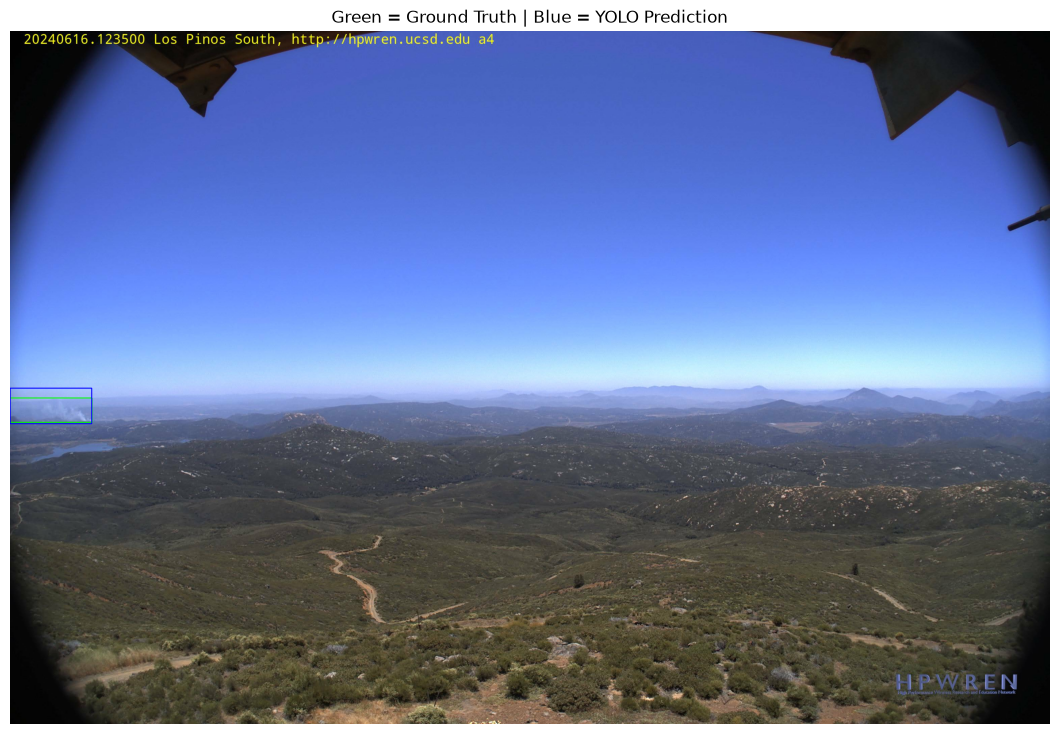

Ground-truth label exists: True
Predicted boxes: 1
IoU between predicted and annotated boxes:
tensor([[0.6879]])


In [12]:
# @title
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Image we want to investigate
image_name = "1718566500_+01320.jpg"

# Locate the original image and its annotation
image_path = validation_images_dir / image_name
label_path = validation_labels_dir / f"{Path(image_name).stem}.txt"

# Load the original image
image = cv2.imread(str(image_path))
assert image is not None, f"Image not found: {image_path}"

height, width = image.shape[:2]

# Draw ground-truth boxes in green
if label_path.exists():
    for line in label_path.read_text().splitlines():
        class_id, x, y, w, h = map(float, line.split())

        # Convert normalized YOLO coordinates into pixel coordinates
        x1 = int((x - w / 2) * width)
        y1 = int((y - h / 2) * height)
        x2 = int((x + w / 2) * width)
        y2 = int((y + h / 2) * height)

        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

# Generate predictions using Experiment 1
results = experiment1_best.predict(
    source=str(image_path),
    imgsz=960,
    conf=0.25,
    verbose=False
)

# Draw predicted boxes in blue
for box in results[0].boxes:
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

    cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)

# Convert BGR to RGB for Matplotlib
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display both types of bounding boxes
plt.figure(figsize=(14, 9))
plt.imshow(image)
plt.title("Green = Ground Truth | Blue = YOLO Prediction")
plt.axis("off")
plt.show()

print(f"Ground-truth label exists: {label_path.exists()}")
print(f"Predicted boxes: {len(results[0].boxes)}")

from ultralytics.utils.metrics import box_iou
import torch

# Compare the predicted boxes with the original annotation
pred_boxes = results[0].boxes.xyxy.cpu()

# ground_truth_boxes should contain the original annotation
# coordinates in pixel-space xyxy format.
ground_truth_boxes = torch.tensor(
    [
        [
            (x - w / 2) * width,
            (y - h / 2) * height,
            (x + w / 2) * width,
            (y + h / 2) * height
        ]
        for _, x, y, w, h in (
            map(float, line.split())
            for line in label_path.read_text().splitlines()
        )
    ],
    dtype=torch.float32
)

ious = box_iou(pred_boxes, ground_truth_boxes)

print("IoU between predicted and annotated boxes:")
print(ious)

### Zoom in on the annotated smoke region

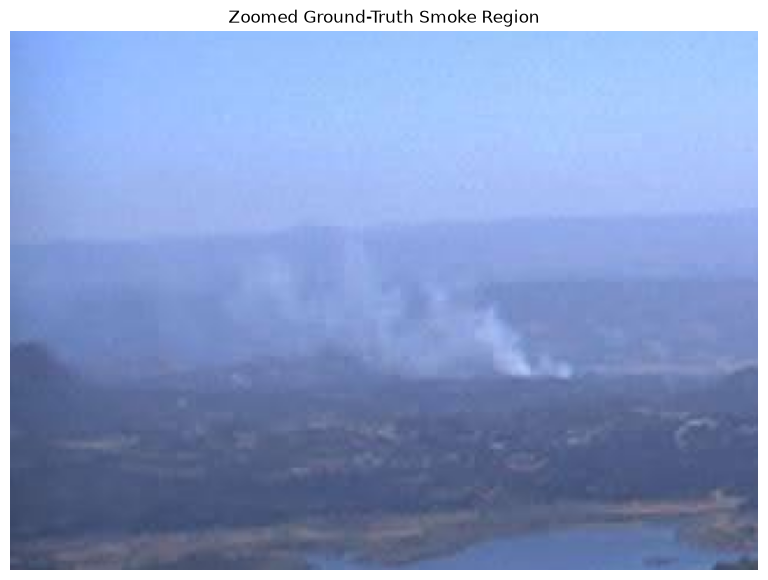

In [13]:
# @title
# ERROR ANALYSIS: Zoom in on the ground-truth smoke annotation
#
# This helps us inspect very small plumes without resizing
# the entire image.

original = cv2.imread(str(image_path))
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

# Read the first ground-truth bounding box
_, x, y, w, h = map(
    float,
    label_path.read_text().splitlines()[0].split()
)

img_h, img_w = original.shape[:2]

# Convert normalized coordinates to pixel coordinates
x1 = int((x - w / 2) * img_w)
y1 = int((y - h / 2) * img_h)
x2 = int((x + w / 2) * img_w)
y2 = int((y + h / 2) * img_h)

# Include surrounding scenery for context
padding = 80

crop = original[
    max(0, y1 - padding):min(img_h, y2 + padding),
    max(0, x1 - padding):min(img_w, x2 + padding)
]

plt.figure(figsize=(10, 7))
plt.imshow(crop)
plt.title("Zoomed Ground-Truth Smoke Region")
plt.axis("off")
plt.show()

### Find examples with correctly matched detections

In [14]:
# @title
# Find validation images with at least one correct smoke detection
# and no false positives or false negatives.

successful_images = []

for item in error_summary:
    if item["false_positives"] == 0 and item["false_negatives"] == 0:
        image_name = item["image"]

        # Confirm that YOLO actually detected smoke
        result = next(
            (r for r in error_analysis_results
             if Path(r.path).name == image_name),
            None
        )

        if result is not None and len(result.boxes) > 0:
            successful_images.append(image_name)

print(f"Successful detection images: {len(successful_images)}")

print("\nFirst 10 successful images:")
for name in successful_images[:10]:
    print(name)

Successful detection images: 50

First 10 successful images:
1717877471_+00300.jpg
1717877531_+00360.jpg
1718565601_+00421.jpg
1718566500_+01320.jpg
1718566561_+01381.jpg
1719855351_+00301.jpg
1719855771_+00721.jpg
1719855831_+00781.jpg
1719856010_+00960.jpg
1719856192_+01142.jpg


## 7. Experiment 3 - Smoke-free Images

In [7]:
from pathlib import Path
import pandas as pd

# Find Experiment 3's training history
experiment3_dir = EXPERIMENTS_DIR / "experiment_3_yolo11s"
results_path = experiment3_dir / "results.csv"

if results_path.exists():
    results = pd.read_csv(results_path)
    results.columns = results.columns.str.strip()

    print("Completed epochs:", len(results))
    print("Last recorded epoch:", results["epoch"].iloc[-1])
    print("Target epochs: 50")
else:
    print("Training history not found.")
    print("We can still evaluate the saved best.pt checkpoint.")

Completed epochs: 48
Last recorded epoch: 48
Target epochs: 50


## 8. Next experiment — planning only

**Experiment 4:** Compare a carefully selected subset of verified hard negatives, with recordings reserved for independent smoke-free evaluation. Use a **new dataset directory** and new experiment name; never overwrite Experiment 2. Keep training settings controlled when comparing datasets.

The previous three training runs are preserved in the **original notebook** and their saved checkpoints. This cleaned copy intentionally has no `model.train()` calls.

In [6]:
from pathlib import Path
import re

# --------------------------------------------------
# Dataset paths
# --------------------------------------------------

negative_images_dir = PROJECT_DIR / "negative_images"
negative_labels_dir = PROJECT_DIR / "negative_labels"

training_images_dir = DATASETS_DIR / "experiment_2" / "images" / "train"
validation_images_dir = DATASETS_DIR / "experiment_2" / "images" / "val"

# --------------------------------------------------
# FIgLib recording identification
# --------------------------------------------------

def get_recording_id(filename):
    # Extract the timestamp and signed offset from the filename
    match = re.match(
        r"^(\d+)_([+-]\d+)\.(jpg|jpeg|png)$",
        filename,
        re.IGNORECASE
    )

    if not match:
        return None

    timestamp = int(match.group(1))
    offset = int(match.group(2))

    # All frames from the same event share this ID
    return timestamp - offset


def collect_recordings(folder):
    # Find all unique recording IDs inside a folder
    recordings = set()

    for image_path in folder.rglob("*"):
        if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue

        recording_id = get_recording_id(image_path.name)

        if recording_id is not None:
            recordings.add(recording_id)

    return recordings


# --------------------------------------------------
# Collect existing recording IDs
# --------------------------------------------------

train_recordings = collect_recordings(training_images_dir)
val_recordings = collect_recordings(validation_images_dir)
negative_recordings = collect_recordings(negative_images_dir)

print("Training recordings:", len(train_recordings))
print("Validation recordings:", len(val_recordings))
print("Negative recordings:", len(negative_recordings))

print("\nNegative overlap with training:",
      len(negative_recordings & train_recordings))

print("Negative overlap with validation:",
      len(negative_recordings & val_recordings))

Training recordings: 37
Validation recordings: 8
Negative recordings: 26

Negative overlap with training: 5
Negative overlap with validation: 0


In [7]:
from collections import defaultdict

# Group negative images by their original FIgLib recording
negative_by_recording = defaultdict(list)

for image_path in negative_images_dir.glob("*"):
    if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue

    recording_id = get_recording_id(image_path.name)

    if recording_id is not None:
        negative_by_recording[recording_id].append(image_path)

# Identify recordings that have never appeared in training or validation
new_recordings = {
    recording_id: images
    for recording_id, images in negative_by_recording.items()
    if recording_id not in train_recordings
    and recording_id not in val_recordings
}

print("Total negative recordings:", len(negative_by_recording))
print("Previously used in training:",
      len(set(negative_by_recording) & train_recordings))
print("New recordings available:", len(new_recordings))

print("\nNew recording image counts:")
for recording_id, images in sorted(new_recordings.items()):
    print(f"{recording_id}: {len(images)} images")

Total negative recordings: 26
Previously used in training: 5
New recordings available: 21

New recording image counts:
1468266071: 40 images
1468872421: 40 images
1468872498: 20 images
1468872972: 20 images
1469223121: 35 images
1469226498: 20 images
1479064369: 40 images
1479066933: 40 images
1495296879: 14 images
1495301827: 40 images
1497049647: 40 images
1497385096: 40 images
1498416078: 40 images
1498579057: 40 images
1498581432: 40 images
1499546263: 80 images
1499787397: 40 images
1499806131: 40 images
1499806193: 40 images
1499806467: 40 images
1499806611: 40 images


In [8]:
# --------------------------------------------------
# Reserve complete recordings for negative evaluation
# --------------------------------------------------

evaluation_recording_ids = {
    1468266071,
    1479064369,
    1495301827,
    1499966161,
}

# Ensure none of these recordings appeared in training or validation
assert not (evaluation_recording_ids & train_recordings)
assert not (evaluation_recording_ids & val_recordings)

# Separate the negative images by recording
evaluation_negatives = [
    image
    for recording_id in evaluation_recording_ids
    for image in negative_by_recording[recording_id]
]

training_negative_pool = [
    image
    for recording_id, images in negative_by_recording.items()
    if recording_id not in evaluation_recording_ids
    for image in images
]

print("Reserved evaluation images:", len(evaluation_negatives))
print("Available training negatives:", len(training_negative_pool))
print("Training recordings available:",
      len(set(negative_by_recording) - evaluation_recording_ids))

Reserved evaluation images: 120
Available training negatives: 849
Training recordings available: 23


In [9]:
import random

# Use a fixed seed so our selection can be reproduced
rng = random.Random(42)

target_negative_count = 300

# Group eligible images by recording
training_negative_groups = {
    recording_id: images.copy()
    for recording_id, images in negative_by_recording.items()
    if recording_id not in evaluation_recording_ids
}

# Shuffle each recording's images reproducibly
for images in training_negative_groups.values():
    rng.shuffle(images)

selected_training_negatives = []

# Select images in rounds, taking one from each recording
# until we reach 300 or run out of available images
while len(selected_training_negatives) < target_negative_count:
    added = False

    for recording_id in sorted(training_negative_groups):
        images = training_negative_groups[recording_id]

        if images:
            selected_training_negatives.append(images.pop())
            added = True

            if len(selected_training_negatives) == target_negative_count:
                break

    if not added:
        break

# Verify that no evaluation images were selected
assert not (
    {p.name for p in selected_training_negatives}
    & {p.name for p in evaluation_negatives}
)

print("Selected training negatives:", len(selected_training_negatives))
print("Reserved evaluation negatives:", len(evaluation_negatives))
print("Unique training recordings:",
      len({get_recording_id(p.name) for p in selected_training_negatives}))

Selected training negatives: 300
Reserved evaluation negatives: 120
Unique training recordings: 23


In [19]:
from pathlib import Path
import shutil

# ============================================================
# EXPERIMENT 4 — DATASET SETUP AND VERIFICATION
# ============================================================

# 1. Establish project paths
PROJECT_DIR = Path(r"D:\Projects\Wildfire_Smoke_Project")
DATASETS_DIR = PROJECT_DIR / "datasets"
EXPERIMENTS_DIR = PROJECT_DIR / "experiments"

experiment4_dir = DATASETS_DIR / "experiment_4"
source_dir = DATASETS_DIR / "experiment_2"

train_images_dir = experiment4_dir / "images" / "train"
train_labels_dir = experiment4_dir / "labels" / "train"
val_images_dir = experiment4_dir / "images" / "val"
val_labels_dir = experiment4_dir / "labels" / "val"

# 2. Verify the existing Experiment 4 training dataset
# Do not recreate or overwrite the 933 training examples.
assert train_images_dir.is_dir(), "Experiment 4 training images folder missing"
assert train_labels_dir.is_dir(), "Experiment 4 training labels folder missing"

def get_images(folder):
    return sorted(
        p for p in folder.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

train_images = get_images(train_images_dir)
train_labels = list(train_labels_dir.glob("*.txt"))

assert len(train_images) == 933, f"Expected 933 training images, found {len(train_images)}"
assert len(train_labels) == 933, f"Expected 933 training labels, found {len(train_labels)}"

# 3. Restore validation images and labels from Experiment 2
# This does not modify Experiment 2 or the training dataset.
for subfolder in ("images", "labels"):
    source = source_dir / subfolder / "val"
    destination = experiment4_dir / subfolder / "val"

    assert source.is_dir(), f"Missing source validation folder: {source}"
    destination.mkdir(parents=True, exist_ok=True)

    for file_path in source.iterdir():
        if file_path.is_file():
            # Copy only files that are missing
            target = destination / file_path.name
            if not target.exists():
                shutil.copy2(file_path, target)

# 4. Recreate the YOLO configuration file
yaml_path = experiment4_dir / "data.yaml"

yaml_content = f"""path: {experiment4_dir.as_posix()}
train: images/train
val: images/val
nc: 1
names:
  0: smoke
"""

yaml_path.write_text(yaml_content, encoding="utf-8")

# 5. Verify all images have matching label files
val_images = get_images(val_images_dir)
val_labels = list(val_labels_dir.glob("*.txt"))

for split, images, label_dir in (
    ("train", train_images, train_labels_dir),
    ("val", val_images, val_labels_dir),
):
    missing = [
        image.name
        for image in images
        if not (label_dir / f"{image.stem}.txt").exists()
    ]
    assert not missing, f"{split}: {len(missing)} images missing labels"

assert len(val_images) == 191, f"Expected 191 validation images, found {len(val_images)}"
assert len(val_labels) == 191, f"Expected 191 validation labels, found {len(val_labels)}"

# 6. Confirm the training dataset contains 633 positives and 300 negatives
positive_count = sum(
    bool((train_labels_dir / f"{image.stem}.txt").read_text(encoding="utf-8").strip())
    for image in train_images
)
negative_count = len(train_images) - positive_count

assert positive_count == 633
assert negative_count == 300

# 7. Print final summary
print("EXPERIMENT 4 — DATASET READY")
print("-" * 40)
print("Training positives:", positive_count)
print("Training negatives:", negative_count)
print("Total training images:", len(train_images))
print("Training labels:", len(train_labels))
print("Validation images:", len(val_images))
print("Validation labels:", len(val_labels))
print("YAML exists:", yaml_path.is_file())
print("Dataset:", experiment4_dir)
print("\nAll checks passed!")

EXPERIMENT 4 — DATASET READY
----------------------------------------
Training positives: 633
Training negatives: 300
Total training images: 933
Training labels: 933
Validation images: 191
Validation labels: 191
YAML exists: True
Dataset: D:\Projects\Wildfire_Smoke_Project\datasets\experiment_4

All checks passed!


In [11]:
# Collect recording IDs from the new Experiment 4 dataset
exp4_train_recordings = collect_recordings(
    experiment4_dir / "images" / "train"
)

exp4_val_recordings = collect_recordings(
    experiment4_dir / "images" / "val"
)

reserved_recordings = {
    get_recording_id(image.name)
    for image in evaluation_negatives
}

# Check for recording overlap between dataset partitions
train_val_overlap = exp4_train_recordings & exp4_val_recordings
train_reserved_overlap = exp4_train_recordings & reserved_recordings
val_reserved_overlap = exp4_val_recordings & reserved_recordings

print("Training/validation overlap:", len(train_val_overlap))
print("Training/reserved negatives overlap:", len(train_reserved_overlap))
print("Validation/reserved negatives overlap:", len(val_reserved_overlap))

# All three checks must pass before training
assert not train_val_overlap
assert not train_reserved_overlap
assert not val_reserved_overlap

print("\nDataset separation verified!")

Training/validation overlap: 0
Training/reserved negatives overlap: 0
Validation/reserved negatives overlap: 0

Dataset separation verified!


In [ ]:
from ultralytics import YOLO

# Use the existing Experiment 4 dataset
experiment4_dir = DATASETS_DIR / "experiment_4"

# Load the original pretrained model
model_exp4 = YOLO("yolo11n.pt")

# Train Experiment 4 with reduced memory usage.
results_exp4 = model_exp4.train(
    data=str(experiment4_dir / "data.yaml"),
    epochs=50,
    imgsz=960,
    batch=4,
    device=0,
    seed=42,
    deterministic=True,
    workers=0,       # Disable multiprocessing for image loading
    cache=False,     # Avoid caching images in RAM
    project=str(EXPERIMENTS_DIR),
    name="experiment_4_expanded_negatives_batch4_retry",
    exist_ok=False,
)

New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.215  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 SUPER, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Projects\Wildfire_Smoke_Project\datasets\experiment_4\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_de